# code_057 · Domain features and interactions

**Book:** section 12.1. A self-contained feature-engineering laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_12_GUIDE.md), [run evidence](../CHAPTER_12_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_057).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. These comparisons expose representation assumptions, fitting boundaries and operational constraints without field-validity, causal or universal feature-selection claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1257;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1257


<a id="hypothesis"></a>
## Encode a declared bending hypothesis

Generate 600 independent, idealized simply supported members under a central point load. Load F=20–100 kN, span L=2–6 m and flexural rigidity EI=4–16 MN m² are independent uniforms. The small-deflection homogeneous Euler–Bernoulli reference gives delta=F*L**3/(48*EI); target mm = .2+1.08*delta_mm+Normal(0,.1). This is a teaching generator with known boundary/loading assumptions, not a real structural assessment. Features admit EI as a supplied measurement available at prediction; there is no inference of unknown stiffness from the future response.

Reserve 300 training, 100 development and 200 final members. Predeclare nested training sizes 40/80/160/300. At each size compare raw [F,L,EI] with standardization/Ridge alpha=.01; degree-two polynomial expansion with fitted standardization/Ridge .01; and the single beam-inspired delta_mm feature with unpenalized intercept/slope OLS. These procedures deliberately encode different hypothesis classes and domain knowledge. No final curve selects a feature or sample size.


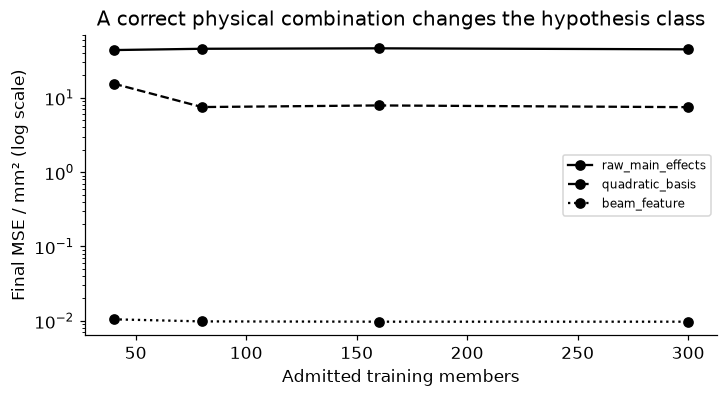

In [2]:
from sklearn.linear_model import Ridge,LinearRegression
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
F=rng.uniform(20,100,600);L=rng.uniform(2,6,600);EI=rng.uniform(4,16,600);raw=np.column_stack([F,L,EI]);delta=1000*(F*1000)*L**3/(48*(EI*1e6));y=.2+1.08*delta+rng.normal(0,.1,600)
tr=np.arange(300);dv=np.arange(300,400);te=np.arange(400,600)
assert (F>0).all() and (L>0).all() and (EI>0).all();assert not set(tr)&set(te)
# delta/L is dimensionless when both lengths are in the same unit.
pi=(F*1000)*L**2/(EI*1e6);np.testing.assert_allclose(delta/(1000*L),pi/48)
np.testing.assert_allclose((F*1000)*L**3/(EI*1e6),F*L**3/(EI*1000))
curves={};fits={}
for n in [40,80,160,300]:
 idx=tr[:n];candidates={'raw_main_effects':(make_pipeline(StandardScaler(),Ridge(alpha=.01)),raw),'quadratic_basis':(make_pipeline(PolynomialFeatures(degree=2,include_bias=False),StandardScaler(),Ridge(alpha=.01)),raw),'beam_feature':(LinearRegression(),delta[:,None])};curves[str(n)]={}
 for name,(fit,A) in candidates.items():
  fit.fit(A[idx],y[idx]);p=fit.predict(A[te]);curves[str(n)][name]={'development_MSE_mm2':float(mean_squared_error(y[dv],fit.predict(A[dv]))),'final_MSE_mm2':float(mean_squared_error(y[te],p))}
  if n==300:fits[name]=(fit,A)
RESULTS['learning_size_metrics']=curves;RESULTS['unit_and_dimensionless_checks']=True;RESULTS['beam_feature_coefficient']=float(fits['beam_feature'][0].coef_[0])
fig,ax=plt.subplots(figsize=(6.5,3.5))
for name,style in zip(['raw_main_effects','quadratic_basis','beam_feature'],['-','--',':']):ax.plot([40,80,160,300],[curves[str(n)][name]['final_MSE_mm2'] for n in [40,80,160,300]],marker='o',ls=style,color='black',label=name)
ax.set(xlabel='Admitted training members',ylabel='Final MSE / mm² (log scale)',yscale='log',title='A correct physical combination changes the hypothesis class');ax.legend(fontsize=8);plt.show()


<a id="limits"></a>
## A useful feature is a falsifiable assumption

The feature wins only within its declared mechanism. Different supports, load positions, shear deformation, nonlinear material response or uncertain stiffness can invalidate it. The generated target includes an affine discrepancy rather than asserting exact beam truth. A zero or uncertain denominator must be investigated, not hidden by arbitrary numerical offsets. Ratios can amplify measurement error; fitted constants and choice among competing formulas require training/development boundaries. This notebook does not establish performance under those unmodeled regimes.


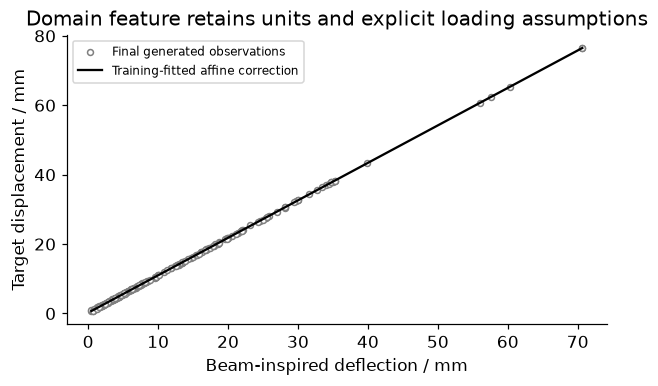

In [3]:
fit,A=fits['beam_feature'];pred=fit.predict(A[te]);fig,ax=plt.subplots(figsize=(5.5,3.4));ax.scatter(delta[te],y[te],s=15,facecolors='white',edgecolors='.5',label='Final generated observations');order=np.argsort(delta[te]);ax.plot(delta[te][order],pred[order],color='black',label='Training-fitted affine correction');ax.set(xlabel='Beam-inspired deflection / mm',ylabel='Target displacement / mm',title='Domain feature retains units and explicit loading assumptions');ax.legend(fontsize=8);plt.show();assert np.isfinite(pred).all()


In [4]:
summary={'example_id':'code_057','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['beam-inspired feature and domain assumptions', 'dimensionless group and unit invariance', 'interaction basis versus raw main effects', 'predeclared learning-size comparisons'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["beam-inspired feature and domain assumptions", "dimensionless group and unit invariance", "interaction basis versus raw main effects", "predeclared learning-size comparisons"], "elapsed_seconds": 0.364, "example_id": "code_057", "hardware": "Darwin arm64 CPU", "results": {"beam_feature_coefficient": 1.079878951075595, "learning_size_metrics": {"160": {"beam_feature": {"development_MSE_mm2": 0.012188318476849895, "final_MSE_mm2": 0.009739232833591011}, "quadratic_basis": {"development_MSE_mm2": 5.099037732348179, "final_MSE_mm2": 7.893233289459147}, "raw_main_effects": {"development_MSE_mm2": 28.55024268067333, "final_MSE_mm2": 46.29425219206833}}, "300": {"beam_feature": {"development_MSE_mm2": 0.012181339506890447, "final_MSE_mm2": 0.00973899085170241}, "quadratic_basis": {"development_MSE_mm2": 5.432559200310428, "final_MSE_mm2": 7.484463858930859}, "raw_main_effects": {"development_MSE_mm2": 34.00655664391106, "final_MSE_mm2": 44.89